In [1]:
import requests
import pandas as pd
import re
from bs4 import BeautifulSoup

In [2]:
url = "https://ev-database.org/"
headers = {"User-Agent": "Mozilla/5.0"}

response = requests.get(url, headers=headers, timeout=30)

print("Status Code:", response.status_code)
print("HTML Length:", len(response.text))

Status Code: 200
HTML Length: 8968150


In [3]:
soup = BeautifulSoup(response.text, "html.parser")

In [4]:
# Extract Brand
brands = []

for card in soup.select("div.list-item"):
    title = card.select_one("h2 a.title")
    brand_tag = title.find("span", recursive=False) if title else None

    brand = brand_tag.get_text(" ", strip=True) if brand_tag else None
    brands.append(brand)

print("Total brands extracted:", len(brands))

for brand in brands[:10]:
    print(brand)


Total brands extracted: 1549
BMW
MG
BMW
Tesla
Fiat
CUPRA
CUPRA
XPENG
BMW
Hyundai


In [5]:
models = []

for card in soup.select("div.list-item"):
    title = card.select_one("h2 a.title")
    model_tag = title.select_one("span.model") if title else None

    model = model_tag.get_text(" ", strip=True) if model_tag else None
    models.append(model)

print("\nTotal models extracted:", len(models))

for model in models[:10]:
    print(model)


Total models extracted: 1549
i3 50 xDrive (MY27)
MG4 Electric 64 kWh (MY22-25)
iX xDrive40
Model 3 RWD (Highland)
500e Hatchback 42 kWh
Born 150 kW - 58 kWh (MY22-24)
Born 170 kW - 77 kWh (MY22-24)
L03 RWD Long Range
iX3 50 xDrive (MY26)
IONIQ 3 61 kWh (MY27)


In [6]:

# Extract Model Year
model_years = []

for model in models:
    year_match = re.search(r"MY(\d{2})", model or "")

    if year_match:
        year = 2000 + int(year_match.group(1))
    else:
        year = None

    model_years.append(year)

print("Total model years extracted:", len(model_years))

for year in model_years[:10]:
    print(year)


Total model years extracted: 1549
2027
2022
None
None
None
2022
2022
None
2026
2027


In [7]:

# Extract Price
prices = []

for card in soup.select("div.list-item"):
    card_text = card.get_text(" ", strip=True)

    price_match = re.search(r"[€£]\s?[\d,]+(?:\.\d+)?", card_text)

    if price_match:
        price = price_match.group(0)
    else:
        price = None

    prices.append(price)

print("Total prices checked:", len(prices))
print("Prices found:", sum(price is not None for price in prices))

for price in prices[:10]:
    print(price)


Total prices checked: 1549
Prices found: 1549
€88
€103
€225
€88
€117
€110
€103
€94
€110
€80


In [8]:

# Extract Battery Capacity
battery_capacities = []

for card in soup.select("div.list-item"):
    battery = None

    for element in card.select("[data-tooltip]"):
        category = element.get("data-tooltip", "").lower()

        if "battery capacity" in category:
            value = element.get_text(" ", strip=True)
            match = re.search(r"(\d+(?:\.\d+)?)\s*kWh", value, re.IGNORECASE)

            if match:
                battery = float(match.group(1))
            break

    battery_capacities.append(battery)

print("Total vehicles checked:", len(battery_capacities))
print("Battery capacity values found:", sum(x is not None for x in battery_capacities))

for value in battery_capacities[:10]:
    print(value)


Total vehicles checked: 1549
Battery capacity values found: 1549
108.7
61.7
71.0
60.0
37.3
58.0
77.0
69.5
108.7
58.0


In [9]:

# Extract Driving Range
ranges = []

for card in soup.select("div.list-item"):
    driving_range = None

    for element in card.select("[data-tooltip]"):
        category = element.get("data-tooltip", "").lower()

        if "real range under standardized conditions" in category:
            value = element.get_text(" ", strip=True)
            match = re.search(r"(\d+(?:\.\d+)?)\s*km", value, re.IGNORECASE)

            if match:
                driving_range = float(match.group(1))
            break

    ranges.append(driving_range)

print("Total vehicles checked:", len(ranges))
print("Range values found:", sum(x is not None for x in ranges))

for value in ranges[:10]:
    print(value)


Total vehicles checked: 1549
Range values found: 1549
720.0
360.0
360.0
450.0
235.0
350.0
450.0
420.0
645.0
375.0


In [10]:
# Extract Energy Consumption
Energy_Consumption_Wh_km = []

for card in soup.select("div.list-item"):
    efficiency = None

    for element in card.select("[data-tooltip]"):
        category = element.get("data-tooltip", "").lower()

        if "efficiency under standardized conditions" in category:
            value = element.get_text(" ", strip=True)
            match = re.search(r"(\d+(?:\.\d+)?)\s*Wh/km", value, re.IGNORECASE)

            if match:
                efficiency = float(match.group(1))
            break

    Energy_Consumption_Wh_km.append(efficiency)

print("Total vehicles checked:", len(Energy_Consumption_Wh_km))
print("Values found:", sum(x is not None for x in Energy_Consumption_Wh_km))

for value in Energy_Consumption_Wh_km[:10]:
    print(value)

Total vehicles checked: 1549
Values found: 1549
151.0
171.0
197.0
133.0
159.0
166.0
171.0
165.0
169.0
155.0


In [11]:
# Extract Fast Charging Power
Fast_Charging_Power_kW = []

for card in soup.select("div.list-item"):
    charging_power = None

    for element in card.select("[data-tooltip]"):
        category = element.get("data-tooltip", "").lower()

        if "average charging power over a charging session" in category:
            value = element.get_text(" ", strip=True)
            match = re.search(r"(\d+(?:\.\d+)?)\s*kW", value, re.IGNORECASE)

            if match:
                charging_power = float(match.group(1))
            break

    Fast_Charging_Power_kW.append(charging_power)

print("Total vehicles checked:", len(Fast_Charging_Power_kW))
print("Values found:", sum(x is not None for x in Fast_Charging_Power_kW))

for value in Fast_Charging_Power_kW[:10]:
    print(value)

Total vehicles checked: 1549
Values found: 1549
230.0
107.0
92.0
110.0
65.0
75.0
103.0
150.0
230.0
85.0


In [12]:
# Check charging-related categories in all vehicles
for card in soup.select("div.list-item"):
    for element in card.select("[data-tooltip]"):
        category = element.get("data-tooltip", "").lower()

        if "charging" in category:
            print(category, ":", element.get_text(" ", strip=True))

bi-directional charging possible : V2
vehicle-2-load bi-directional charging possible : L
vehicle-2-home bi-directional charging possible : H
vehicle-2-grid bi-directional charging possible : G
total range at highway speed using a single 15 minute charging stop : 1-Stop Range 895 km 895
average charging power over a charging session of 10% to 80% soc : Fastcharge 230 kW 230
bi-directional charging possible : V2
vehicle-2-load bi-directional charging possible : L
vehicle-2-home bi-directional charging not possible : H
vehicle-2-grid bi-directional charging not possible : G
total range at highway speed using a single 15 minute charging stop : 1-Stop Range 401 km 401
average charging power over a charging session of 10% to 80% soc : Fastcharge 107 kW 107
bi-directional charging not possible : V2
vehicle-2-load bi-directional charging not possible : L
vehicle-2-home bi-directional charging not possible : H
vehicle-2-grid bi-directional charging not possible : G
total range at highway speed

In [13]:
# Check Top Speed category
for card in soup.select("div.list-item")[:5]:
    for element in card.select("[data-tooltip]"):
        category = element.get("data-tooltip", "").lower()

        if "top speed" in category:
            print(category, ":", element.get_text(" ", strip=True))

In [14]:

# Check actual top-speed tooltip names and values
for card in soup.select("div.list-item")[:5]:
    for element in card.select("[data-tooltip]"):
        category = element.get("data-tooltip", "").lower()

        if "speed" in category or "km/h" in category:
            print("Category:", category)
            print("Value:", element.get_text(" ", strip=True))
            print("---")


Category: time to accelerate from standstill to 100 km/h (62 mph)
Value: 0-100 4.7 sec 4.7
---
Category: total range at highway speed using a single 15 minute charging stop
Value: 1-Stop Range 895 km 895
---
Category: time to accelerate from standstill to 100 km/h (62 mph)
Value: 0-100 7.9 sec 7.9
---
Category: total range at highway speed using a single 15 minute charging stop
Value: 1-Stop Range 401 km 401
---
Category: time to accelerate from standstill to 100 km/h (62 mph)
Value: 0-100 6.1 sec 6.1
---
Category: total range at highway speed using a single 15 minute charging stop
Value: 1-Stop Range 382 km 382
---
Category: time to accelerate from standstill to 100 km/h (62 mph)
Value: 0-100 6.2 sec 6.2
---
Category: total range at highway speed using a single 15 minute charging stop
Value: 1-Stop Range 533 km 533
---
Category: time to accelerate from standstill to 100 km/h (62 mph)
Value: 0-100 9.0 sec 9
---
Category: total range at highway speed using a single 15 minute charging st

In [15]:
# Extract Acceleration Time
Acceleration_0_100_sec = []

for card in soup.select("div.list-item"):
    acceleration = None

    for element in card.select("[data-tooltip]"):
        category = element.get("data-tooltip", "").lower()

        if "time to accelerate from standstill to 100 km/h" in category:
            value = element.get_text(" ", strip=True)
            match = re.search(r"(\d+(?:\.\d+)?)\s*sec", value, re.IGNORECASE)

            if match:
                acceleration = float(match.group(1))
            break

    Acceleration_0_100_sec.append(acceleration)

print("Total vehicles checked:", len(Acceleration_0_100_sec))
print("Acceleration values found:", sum(x is not None for x in Acceleration_0_100_sec))

for value in Acceleration_0_100_sec[:10]:
    print(value)

Total vehicles checked: 1549
Acceleration values found: 1549
4.7
7.9
6.1
6.2
9.0
7.3
7.0
6.6
4.9
9.5


In [16]:

# Extract Number of Seats
Number_of_Seats = []

for card in soup.select("div.list-item"):
    seats = None

    for element in card.select("[data-tooltip]"):
        category = element.get("data-tooltip", "").lower()

        if "number of seats" in category:
            value = element.get_text(" ", strip=True)
            match = re.search(r"\d+", value)

            if match:
                seats = int(match.group())
            break

    Number_of_Seats.append(seats)

print("Total vehicles checked:", len(Number_of_Seats))
print("Seat values found:", sum(x is not None for x in Number_of_Seats))

for value in Number_of_Seats[:10]:
    print(value)


Total vehicles checked: 1549
Seat values found: 1549
5
5
5
5
4
5
4
5
5
5


In [17]:

# Extract Vehicle Type
Vehicle_Type = []

for card in soup.select("div.list-item"):
    vehicle_type = None

    for element in card.select("[data-tooltip]"):
        category = element.get("data-tooltip", "").lower()
        value = element.get_text(" ", strip=True)

        if "vehicle type" in category:
            vehicle_type = value.strip()
            break

    Vehicle_Type.append(vehicle_type)

print("Total vehicles checked:", len(Vehicle_Type))
print("Vehicle types found:", sum(x is not None for x in Vehicle_Type))

for value in Vehicle_Type[:10]:
    print(value)


Total vehicles checked: 1549
Vehicle types found: 0
None
None
None
None
None
None
None
None
None
None


In [18]:
# Inspect the first vehicle card
first_card = soup.select_one("div.list-item")

print(first_card.get_text(" ", strip=True)[:1000])

BMW i3 50 xDrive (MY27) BMW i3 50 xDrive Available to order since June 2026 D 5 Heatpump Towbar possible -1 V2 L V2XL H V2XH G V2XG Range* 720 km Efficiency* 151 Wh/km Weight 2,280 kg 2280 0-100 4.7 sec 4.7 1-Stop Range 895 km 895 Battery 108.7 kWh 108.7 Fastcharge 230 kW 230 Towing 1,800 kg 1800 Cargo Vol. 451 L 451 Price/range* €88 /km 88 €65,900 €63,301 £53,425 63546 63546 1781740800 946684800 2026 2000 5578 3657 Type 2 CCS Sedan


In [19]:

# Extract actual vehicle price

Price_Euros = []

for card in soup.select("div.list-item"):
    card_text = card.get_text(" ", strip=True)

    # Find all euro amounts in the card
    price_matches = re.findall(r"€\s*([\d,]+)", card_text)

    if price_matches:
        price = int(price_matches[-1].replace(",", ""))
    else:
        price = None

    Price_Euros.append(price)

print("Total vehicles:", len(Price_Euros))
print("Prices found:", sum(x is not None for x in Price_Euros))

for value in Price_Euros[:10]:
    print(value)


Total vehicles: 1549
Prices found: 1549
63301
37570
84998
36990
27999
36939
46989
39990
70584
31995


In [20]:

# Extract Vehicle Weight
Weight_kg = []

for card in soup.select("div.list-item"):
    weight = None

    for element in card.select("[data-tooltip]"):
        category = element.get("data-tooltip", "").lower()

        if "weight (lowest curb weight)" in category:
            value = element.get_text(" ", strip=True)
            match = re.search(r"([\d,]+)\s*kg", value, re.IGNORECASE)

            if match:
                weight = int(match.group(1).replace(",", ""))
            break

    Weight_kg.append(weight)

print("Total vehicles checked:", len(Weight_kg))
print("Weight values found:", sum(x is not None for x in Weight_kg))

for value in Weight_kg[:10]:
    print(value)


Total vehicles checked: 1549
Weight values found: 1549
2280
1726
2440
1847
1365
1811
1946
2015
2360
1555


In [21]:

# Extract Towing Capacity
Towing_Capacity_kg = []

for card in soup.select("div.list-item"):
    towing = None

    for element in card.select("[data-tooltip]"):
        category = element.get("data-tooltip", "").lower()

        if "towing capacity" in category or category == "towing":
            value = element.get_text(" ", strip=True)
            match = re.search(r"([\d,]+)\s*kg", value, re.IGNORECASE)

            if match:
                towing = int(match.group(1).replace(",", ""))
            break

    Towing_Capacity_kg.append(towing)

print("Total vehicles checked:", len(Towing_Capacity_kg))
print("Towing values found:", sum(x is not None for x in Towing_Capacity_kg))

for value in Towing_Capacity_kg[:10]:
    print(value)


Total vehicles checked: 1549
Towing values found: 1501
1800
500
2500
1000
0
0
0
1500
2000
750


In [22]:

# Extract Cargo Volume
Cargo_Volume_L = []

for card in soup.select("div.list-item"):
    cargo = None

    for element in card.select("[data-tooltip]"):
        category = element.get("data-tooltip", "").lower()

        if "cargo volume" in category:
            value = element.get_text(" ", strip=True)
            match = re.search(r"([\d,]+)\s*L\b", value, re.IGNORECASE)

            if match:
                cargo = int(match.group(1).replace(",", ""))
            break

    Cargo_Volume_L.append(cargo)

print("Total vehicles checked:", len(Cargo_Volume_L))
print("Cargo volume values found:", sum(x is not None for x in Cargo_Volume_L))

for value in Cargo_Volume_L[:10]:
    print(value)


Total vehicles checked: 1549
Cargo volume values found: 1483
451
363
500
682
185
385
385
456
578
441


In [23]:

# Extract 15-Minute Charging Stop Range
Charging_Stop_Range_km = []

for card in soup.select("div.list-item"):
    charging_range = None

    for element in card.select("[data-tooltip]"):
        category = element.get("data-tooltip", "").lower()

        if "total range at highway speed using a single 15 minute charging stop" in category:
            value = element.get_text(" ", strip=True)
            match = re.search(r"([\d,]+)\s*km", value, re.IGNORECASE)

            if match:
                charging_range = int(match.group(1).replace(",", ""))
            break

    Charging_Stop_Range_km.append(charging_range)

print("Total vehicles checked:", len(Charging_Stop_Range_km))
print("Values found:", sum(x is not None for x in Charging_Stop_Range_km))

for value in Charging_Stop_Range_km[:10]:
    print(value)


Total vehicles checked: 1549
Values found: 1549
895
401
382
533
260
369
479
508
785
396


In [24]:

# Combine all extracted categories into one DataFrame

print("Checking list lengths:")
print("Brands:", len(brands))
print("Models:", len(models))
print("Model Years:", len(model_years))
print("Prices:", len(Price_Euros))
print("Battery Capacity:", len(battery_capacities))
print("Driving Range:", len(ranges))
print("Efficiency:", len(Energy_Consumption_Wh_km))
print("Fast Charging Power:", len(Fast_Charging_Power_kW))
print("Acceleration:", len(Acceleration_0_100_sec))
print("Seats:", len(Number_of_Seats))
print("Weight:", len(Weight_kg))
print("Towing Capacity:", len(Towing_Capacity_kg))
print("Cargo Volume:", len(Cargo_Volume_L))
print("Charging Stop Range:", len(Charging_Stop_Range_km))


Checking list lengths:
Brands: 1549
Models: 1549
Model Years: 1549
Prices: 1549
Battery Capacity: 1549
Driving Range: 1549
Efficiency: 1549
Fast Charging Power: 1549
Acceleration: 1549
Seats: 1549
Weight: 1549
Towing Capacity: 1549
Cargo Volume: 1549
Charging Stop Range: 1549


In [25]:

# Create the EV DataFrame

ev_df = pd.DataFrame({
    "Brand": brands,
    "Model": models,
    "Model_Year": model_years,
    "Price_Euros": Price_Euros,
    "Battery_Capacity_kWh": battery_capacities,
    "Driving_Range_km": ranges,
    "Energy_Consumption_Wh_km": Energy_Consumption_Wh_km,
    "Fast_Charging_Power_kW": Fast_Charging_Power_kW,
    "Acceleration_0_100_sec": Acceleration_0_100_sec,
    "Number_of_Seats": Number_of_Seats,
    "Weight_kg": Weight_kg,
    "Towing_Capacity_kg": Towing_Capacity_kg,
    "Cargo_Volume_L": Cargo_Volume_L,
    "Charging_Stop_Range_km": Charging_Stop_Range_km
})

print("Dataset Shape:", ev_df.shape)
display(ev_df.head(10))


Dataset Shape: (1549, 14)


,Brand,Model,Model_Year,Price_Euros,Battery_Capacity_kWh,Driving_Range_km,Energy_Consumption_Wh_km,Fast_Charging_Power_kW,Acceleration_0_100_sec,Number_of_Seats,Weight_kg,Towing_Capacity_kg,Cargo_Volume_L,Charging_Stop_Range_km
0,BMW,i3 50 xDrive (MY27),2027.0,63301,108.7,720.0,151.0,230.0,4.7,5,2280,1800.0,451.0,895
1,MG,MG4 Electric 64 kWh (MY22-25),2022.0,37570,61.7,360.0,171.0,107.0,7.9,5,1726,500.0,363.0,401
2,BMW,iX xDrive40,NaN,84998,71.0,360.0,197.0,92.0,6.1,5,2440,2500.0,500.0,382
3,Tesla,Model 3 RWD (Highland),NaN,36990,60.0,450.0,133.0,110.0,6.2,5,1847,1000.0,682.0,533
4,Fiat,500e Hatchback 42 kWh,NaN,27999,37.3,235.0,159.0,65.0,9.0,4,1365,0.0,185.0,260
5,CUPRA,Born 150 kW - 58 kWh (MY22-24),2022.0,36939,58.0,350.0,166.0,75.0,7.3,5,1811,0.0,385.0,369
6,CUPRA,Born 170 kW - 77 kWh (MY22-24),2022.0,46989,77.0,450.0,171.0,103.0,7.0,4,1946,0.0,385.0,479
7,XPENG,L03 RWD Long Range,NaN,39990,69.5,420.0,165.0,150.0,6.6,5,2015,1500.0,456.0,508
8,BMW,iX3 50 xDrive (MY26),2026.0,70584,108.7,645.0,169.0,230.0,4.9,5,2360,2000.0,578.0,785
9,Hyundai,IONIQ 3 61 kWh (MY27),2027.0,31995,58.0,375.0,155.0,85.0,9.5,5,1555,750.0,441.0,396


In [26]:

# Check missing values

missing_values = ev_df.isnull().sum()

print("Missing Values in Each Column:")
display(missing_values)


Missing Values in Each Column:


Brand                         0
Model                         0
Model_Year                  728
Price_Euros                   0
Battery_Capacity_kWh          0
Driving_Range_km              0
Energy_Consumption_Wh_km      0
Fast_Charging_Power_kW        0
Acceleration_0_100_sec        0
Number_of_Seats               0
Weight_kg                     0
Towing_Capacity_kg           48
Cargo_Volume_L               66
Charging_Stop_Range_km        0
dtype: int64

In [27]:

# Check duplicate records

print("Total duplicate rows:", ev_df.duplicated().sum())


Total duplicate rows: 1


In [28]:

# Remove duplicate rows

ev_df = ev_df.drop_duplicates()

print("Dataset Shape after removing duplicates:", ev_df.shape)
print("Duplicate rows remaining:", ev_df.duplicated().sum())


Dataset Shape after removing duplicates: (1548, 14)
Duplicate rows remaining: 0


In [29]:

# Check dataset size and duplicates

print("Current dataset shape:", ev_df.shape)
print("Total rows in original listing:", len(soup.select("div.list-item")))
print("Duplicate rows currently:", ev_df.duplicated().sum())


Current dataset shape: (1548, 14)
Total rows in original listing: 1549
Duplicate rows currently: 0


In [30]:

# Check data types

print(ev_df.dtypes)


Brand                        object
Model                        object
Model_Year                  float64
Price_Euros                   int64
Battery_Capacity_kWh        float64
Driving_Range_km            float64
Energy_Consumption_Wh_km    float64
Fast_Charging_Power_kW      float64
Acceleration_0_100_sec      float64
Number_of_Seats               int64
Weight_kg                     int64
Towing_Capacity_kg          float64
Cargo_Volume_L              float64
Charging_Stop_Range_km        int64
dtype: object


In [31]:

# Statistical summary of numerical columns

display(ev_df.describe())


,Model_Year,Price_Euros,Battery_Capacity_kWh,Driving_Range_km,Energy_Consumption_Wh_km,Fast_Charging_Power_kW,Acceleration_0_100_sec,Number_of_Seats,Weight_kg,Towing_Capacity_kg,Cargo_Volume_L,Charging_Stop_Range_km
count,821.000000,1548.000000,1548.000000,1548.000000,1548.000000,1548.000000,1548.000000,1548.000000,1548.000000,1500.000000,1482.000000,1548.000000
mean,2024.779537,64640.717700,71.428101,377.729328,191.461886,115.620801,7.261757,5.430879,2109.089147,1033.990667,555.678138,413.854651
std,1.959684,40470.412941,21.362429,114.082421,31.844694,59.004686,2.967716,1.285794,367.343423,753.491158,238.374375,146.405376
min,2011.000000,95.000000,14.500000,85.000000,109.000000,0.000000,2.000000,2.000000,975.000000,0.000000,116.000000,65.000000
25%,2024.000000,41493.750000,58.000000,295.000000,168.000000,78.000000,5.100000,5.000000,1895.750000,147.500000,430.000000,306.750000
50%,2025.000000,53990.000000,73.850000,385.000000,183.000000,105.000000,6.800000,5.000000,2151.000000,1000.000000,520.000000,413.000000
75%,2026.000000,72796.250000,86.000000,460.000000,205.000000,135.000000,8.700000,5.000000,2365.000000,1600.000000,619.000000,519.250000
max,2028.000000,550000.000000,141.000000,720.000000,295.000000,450.000000,22.400000,9.000000,3085.000000,3000.000000,2386.000000,895.000000


In [32]:

# Check extracted prices

print(ev_df["Price_Euros"].head(10).to_list())
print("\nMinimum price:", ev_df["Price_Euros"].min())
print("Maximum price:", ev_df["Price_Euros"].max())

display(ev_df[["Brand", "Model", "Price_Euros"]].head(10))


[63301, 37570, 84998, 36990, 27999, 36939, 46989, 39990, 70584, 31995]

Minimum price: 95
Maximum price: 550000


,Brand,Model,Price_Euros
0,BMW,i3 50 xDrive (MY27),63301
1,MG,MG4 Electric 64 kWh (MY22-25),37570
2,BMW,iX xDrive40,84998
3,Tesla,Model 3 RWD (Highland),36990
4,Fiat,500e Hatchback 42 kWh,27999
5,CUPRA,Born 150 kW - 58 kWh (MY22-24),36939
6,CUPRA,Born 170 kW - 77 kWh (MY22-24),46989
7,XPENG,L03 RWD Long Range,39990
8,BMW,iX3 50 xDrive (MY26),70584
9,Hyundai,IONIQ 3 61 kWh (MY27),31995


In [33]:
print(ev_df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 1548 entries, 0 to 1548
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Brand                     1548 non-null   object 
 1   Model                     1548 non-null   object 
 2   Model_Year                821 non-null    float64
 3   Price_Euros               1548 non-null   int64  
 4   Battery_Capacity_kWh      1548 non-null   float64
 5   Driving_Range_km          1548 non-null   float64
 6   Energy_Consumption_Wh_km  1548 non-null   float64
 7   Fast_Charging_Power_kW    1548 non-null   float64
 8   Acceleration_0_100_sec    1548 non-null   float64
 9   Number_of_Seats           1548 non-null   int64  
 10  Weight_kg                 1548 non-null   int64  
 11  Towing_Capacity_kg        1500 non-null   float64
 12  Cargo_Volume_L            1482 non-null   float64
 13  Charging_Stop_Range_km    1548 non-null   int64  
dtypes: float64(8)

In [34]:
ev_df.isnull().sum()

Brand                         0
Model                         0
Model_Year                  727
Price_Euros                   0
Battery_Capacity_kWh          0
Driving_Range_km              0
Energy_Consumption_Wh_km      0
Fast_Charging_Power_kW        0
Acceleration_0_100_sec        0
Number_of_Seats               0
Weight_kg                     0
Towing_Capacity_kg           48
Cargo_Volume_L               66
Charging_Stop_Range_km        0
dtype: int64

In [35]:
ev_df.isnull().sum() / len(ev_df) * 100

Brand                        0.000000
Model                        0.000000
Model_Year                  46.963824
Price_Euros                  0.000000
Battery_Capacity_kWh         0.000000
Driving_Range_km             0.000000
Energy_Consumption_Wh_km     0.000000
Fast_Charging_Power_kW       0.000000
Acceleration_0_100_sec       0.000000
Number_of_Seats              0.000000
Weight_kg                    0.000000
Towing_Capacity_kg           3.100775
Cargo_Volume_L               4.263566
Charging_Stop_Range_km       0.000000
dtype: float64

In [36]:
# Fill missing values with median
ev_df['Model_Year'] = ev_df['Model_Year'].fillna(ev_df['Model_Year'].median())

In [37]:
ev_df['Towing_Capacity_kg'] = ev_df['Towing_Capacity_kg'].fillna(
    ev_df['Towing_Capacity_kg'].median()
)

In [38]:
ev_df['Cargo_Volume_L'] = ev_df['Cargo_Volume_L'].fillna(
    ev_df['Cargo_Volume_L'].median()
)

In [39]:
ev_df.isnull().sum()

Brand                       0
Model                       0
Model_Year                  0
Price_Euros                 0
Battery_Capacity_kWh        0
Driving_Range_km            0
Energy_Consumption_Wh_km    0
Fast_Charging_Power_kW      0
Acceleration_0_100_sec      0
Number_of_Seats             0
Weight_kg                   0
Towing_Capacity_kg          0
Cargo_Volume_L              0
Charging_Stop_Range_km      0
dtype: int64

In [40]:
ev_df.duplicated().sum()

np.int64(0)

In [41]:
ev_df.describe()


,Model_Year,Price_Euros,Battery_Capacity_kWh,Driving_Range_km,Energy_Consumption_Wh_km,Fast_Charging_Power_kW,Acceleration_0_100_sec,Number_of_Seats,Weight_kg,Towing_Capacity_kg,Cargo_Volume_L,Charging_Stop_Range_km
count,1548.000000,1548.000000,1548.000000,1548.000000,1548.000000,1548.000000,1548.000000,1548.000000,1548.000000,1548.000000,1548.000000,1548.000000
mean,2024.883075,64640.717700,71.428101,377.729328,191.461886,115.620801,7.261757,5.430879,2109.089147,1032.936693,554.156977,413.854651
std,1.430989,40470.412941,21.362429,114.082421,31.844694,59.004686,2.967716,1.285794,367.343423,741.732880,233.345474,146.405376
min,2011.000000,95.000000,14.500000,85.000000,109.000000,0.000000,2.000000,2.000000,975.000000,0.000000,116.000000,65.000000
25%,2025.000000,41493.750000,58.000000,295.000000,168.000000,78.000000,5.100000,5.000000,1895.750000,462.500000,435.000000,306.750000
50%,2025.000000,53990.000000,73.850000,385.000000,183.000000,105.000000,6.800000,5.000000,2151.000000,1000.000000,520.000000,413.000000
75%,2025.000000,72796.250000,86.000000,460.000000,205.000000,135.000000,8.700000,5.000000,2365.000000,1600.000000,607.000000,519.250000
max,2028.000000,550000.000000,141.000000,720.000000,295.000000,450.000000,22.400000,9.000000,3085.000000,3000.000000,2386.000000,895.000000


In [42]:
ev_df['Brand'].nunique()

79

In [43]:
ev_df['Brand'].value_counts().head(10)

Brand
Volkswagen       142
Mercedes-Benz    139
Tesla             98
Ford              76
Audi              75
Porsche           70
Volvo             61
BMW               59
Škoda             55
Kia               52
Name: count, dtype: int64

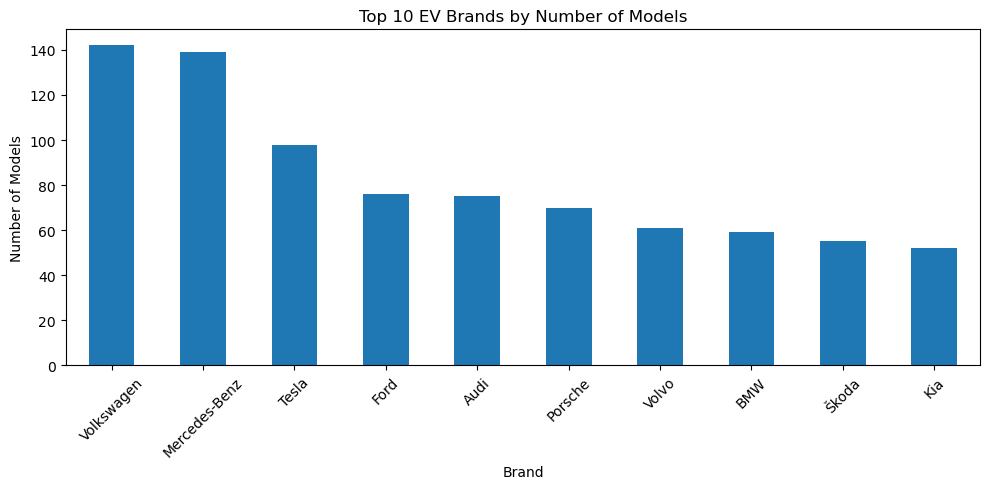

In [44]:
import matplotlib.pyplot as plt

top_brands = ev_df['Brand'].value_counts().head(10)

top_brands.plot(kind='bar', figsize=(10, 5))

plt.title('Top 10 EV Brands by Number of Models')
plt.xlabel('Brand')
plt.ylabel('Number of Models')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

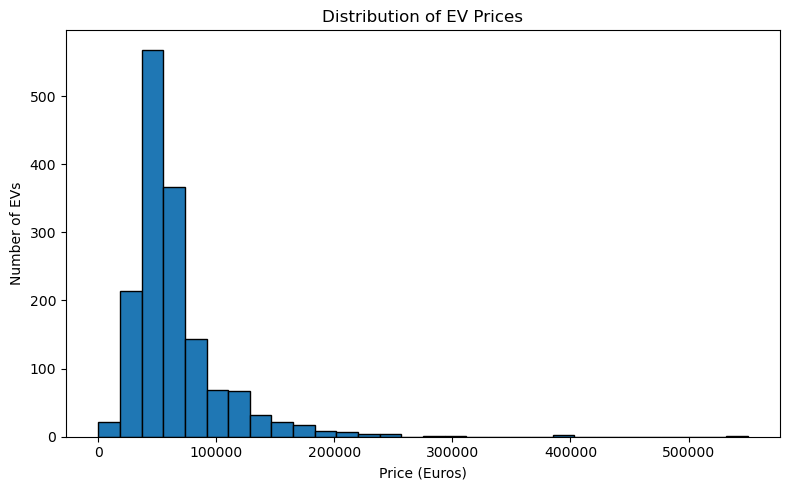

In [45]:
#Histogram — Distribution of EV prices
plt.figure(figsize=(8, 5))

plt.hist(ev_df['Price_Euros'], bins=30, edgecolor='black')

plt.title('Distribution of EV Prices')
plt.xlabel('Price (Euros)')
plt.ylabel('Number of EVs')

plt.tight_layout()
plt.show()

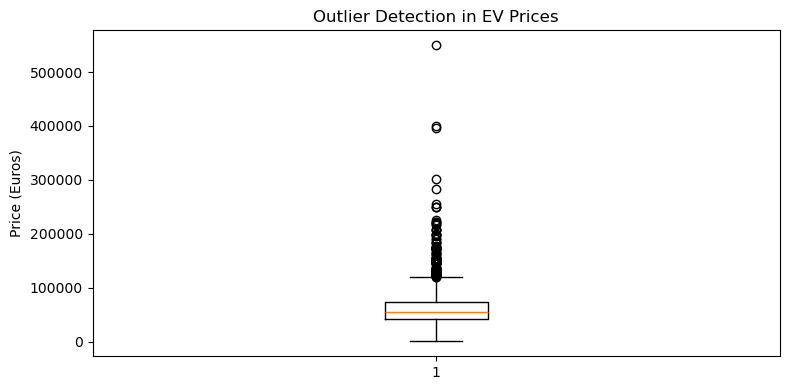

In [46]:
#Box plot — Detect price outliers
plt.figure(figsize=(8, 4))

plt.boxplot(ev_df['Price_Euros'])

plt.title('Outlier Detection in EV Prices')
plt.ylabel('Price (Euros)')

plt.tight_layout()
plt.show()

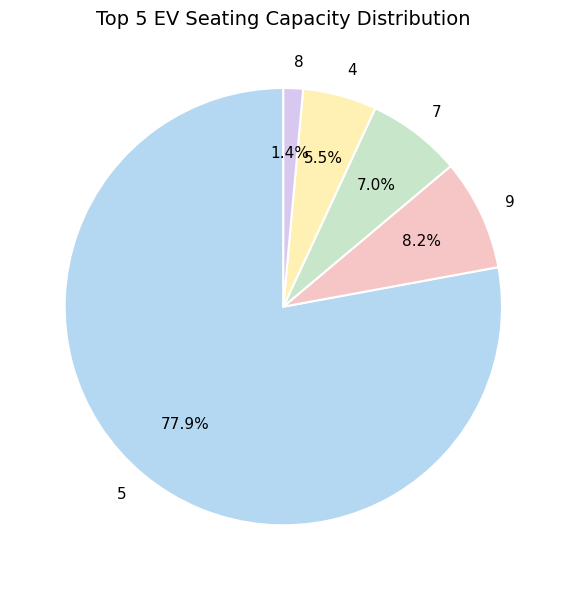

In [55]:
# Top 5 EV Seating Capacity — Pie Chart

import matplotlib.pyplot as plt

seat_counts = ev_df['Number_of_Seats'].value_counts().head(5)

pastel_colors = ['#B5D8F2', '#F6C6C6', '#C8E6C9', '#FFF0B3', '#D8C8F0']

plt.figure(figsize=(8, 6))

plt.pie(
    seat_counts,
    labels=seat_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=pastel_colors,
    pctdistance=0.7,
    labeldistance=1.12,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
    textprops={'fontsize': 11}
)

plt.title('Top 5 EV Seating Capacity Distribution', fontsize=14)
plt.tight_layout()
plt.show()

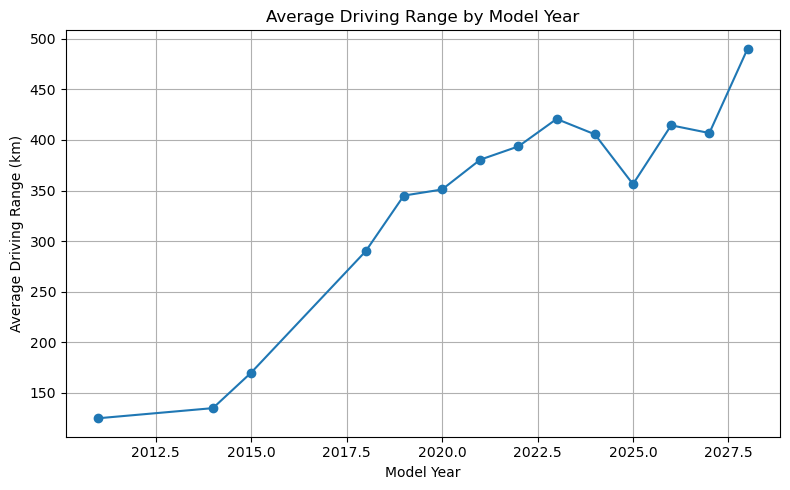

In [49]:
# Line chart — Average driving range by model year

year_range = ev_df.groupby('Model_Year')['Driving_Range_km'].mean()

year_range.plot(kind='line', marker='o', figsize=(8, 5))

plt.title('Average Driving Range by Model Year')
plt.xlabel('Model Year')
plt.ylabel('Average Driving Range (km)')
plt.grid(True)
plt.tight_layout()
plt.show()

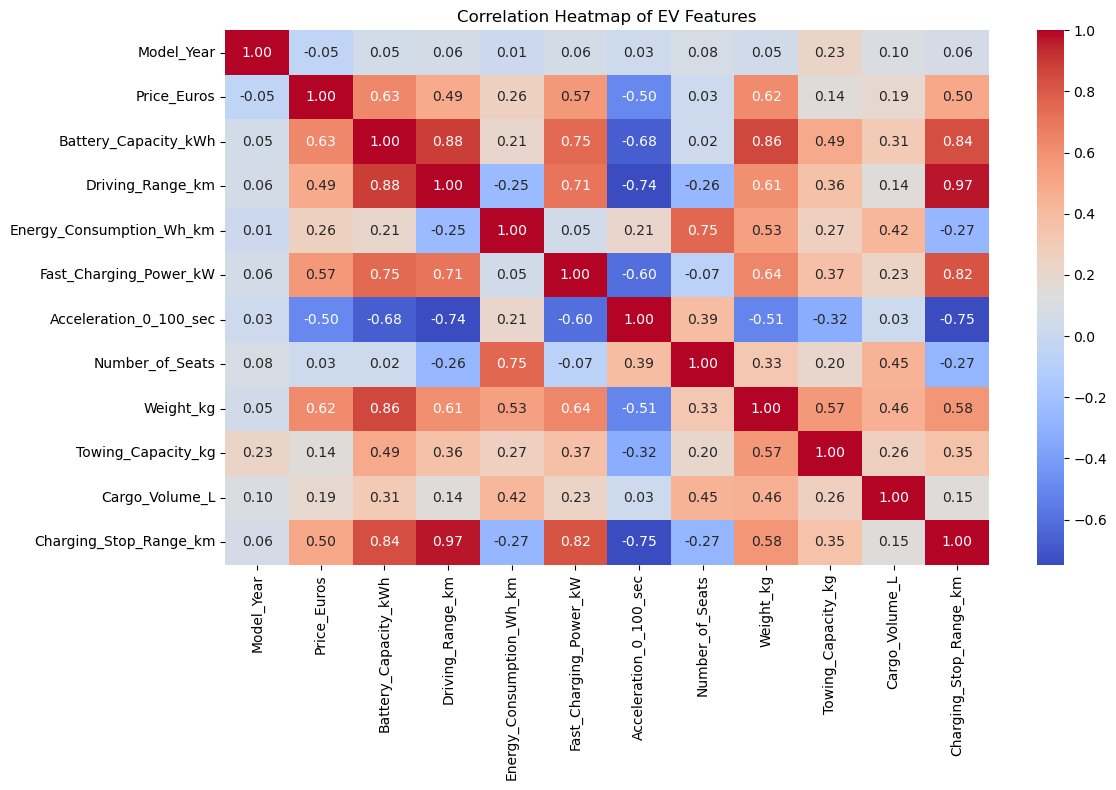

In [50]:
import seaborn as sns

corr = ev_df.select_dtypes(include='number').corr()

plt.figure(figsize=(12, 8))

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap of EV Features')
plt.tight_layout()
plt.show()

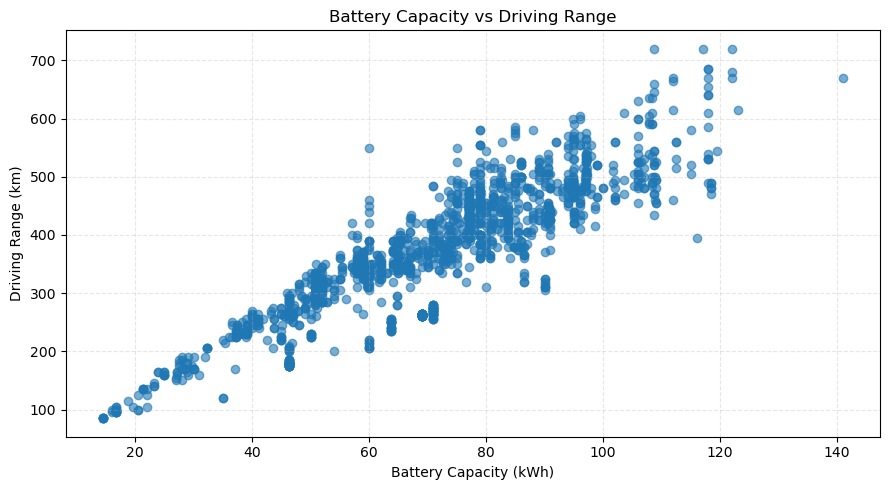

In [51]:

import matplotlib.pyplot as plt

# Scatter Plot: Battery Capacity vs Driving Range
plt.figure(figsize=(9, 5))

plt.scatter(
    ev_df["Battery_Capacity_kWh"],
    ev_df["Driving_Range_km"],
    alpha=0.6
)

plt.title("Battery Capacity vs Driving Range")
plt.xlabel("Battery Capacity (kWh)")
plt.ylabel("Driving Range (km)")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


### Hypothesis Testing

In [52]:
# test-1-->battery vs range
from scipy import stats

corr, p_val = stats.pearsonr(
    ev_df['Battery_Capacity_kWh'],
    ev_df['Driving_Range_km']
)

print('Correlation:', round(corr, 3))
print('P-value:', p_val)

if p_val < 0.05:
    print('Reject H0: Significant relationship')
else:
    print('Fail to reject H0: No significant relationship')


Correlation: 0.884
P-value: 0.0
Reject H0: Significant relationship


In [53]:
# TEST 2: Driving Range by Number of Seats

from scipy import stats

group1 = ev_df.loc[ev_df['Number_of_Seats'] <= 5, 'Driving_Range_km'].dropna()
group2 = ev_df.loc[ev_df['Number_of_Seats'] > 5, 'Driving_Range_km'].dropna()

t_stat, p_val = stats.ttest_ind(group1, group2, equal_var=False)

print('P-value:', p_val)


if p_val < 0.05:
    print('Reject H0: Significant difference')
else:
    print('Fail to reject H0: No significant difference')


P-value: 5.186576720052168e-28
Reject H0: Significant difference


In [54]:
# TEST 3: Energy Consumption by Battery Capacity

   
from scipy import stats

median = ev_df['Battery_Capacity_kWh'].median()

group1 = ev_df.loc[ev_df['Battery_Capacity_kWh'] <= median, 'Energy_Consumption_Wh_km'].dropna()
group2 = ev_df.loc[ev_df['Battery_Capacity_kWh'] > median, 'Energy_Consumption_Wh_km'].dropna()

t_stat, p_val = stats.ttest_ind(group1, group2, equal_var=False)

print('P-value:', p_val)


if p_val < 0.05:
    print('Reject H0: Significant difference')
else:
    print('Fail to reject H0: No significant difference')


P-value: 0.8638212171045717
Fail to reject H0: No significant difference
